# Exploratory Data Analysis — Date Master

**Dataset:** `Date+Master.xlsx` → `Dates` worksheet  
**Coverage:** Daily calendar dates from 1 January 2018 to 31 December 2024.

This notebook follows the same section-based workflow as the reference EDA notebook, adapted for a calendar/date dimension. It checks data quality, validates date attributes, explores yearly/monthly/weekday patterns, and visualizes the calendar coverage. Because this is a date dimension rather than a business-fact dataset, analyses focus on calendar structure rather than sales or other business measures.

## 1. Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Keep Date+Master.xlsx in the same folder as this notebook.
file_path = "Date+Master.xlsx"
dates = pd.read_excel(file_path, sheet_name="Dates", parse_dates=["Master Date"])

dates.head()

,Master Date,Day,Month,Year,WeekDay,WeekDay Name,Month Name,Week Num
0,2018-01-01,1,1,2018,2,Monday,January,1
1,2018-01-02,2,1,2018,3,Tuesday,January,1
2,2018-01-03,3,1,2018,4,Wednesday,January,1
3,2018-01-04,4,1,2018,5,Thursday,January,1
4,2018-01-05,5,1,2018,6,Friday,January,1


## 2. Basic Structure

In [2]:
dates.shape

(2557, 8)

In [3]:
dates.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2557 entries, 0 to 2556
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Master Date   2557 non-null   datetime64[ns]
 1   Day           2557 non-null   int64         
 2   Month         2557 non-null   int64         
 3   Year          2557 non-null   int64         
 4   WeekDay       2557 non-null   int64         
 5   WeekDay Name  2557 non-null   object        
 6   Month Name    2557 non-null   object        
 7   Week Num      2557 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(2)
memory usage: 159.9+ KB


In [4]:
dates.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Master Date,2557,NaN,NaN,NaN,2021-07-02 00:00:00,2018-01-01 00:00:00,2019-10-02 00:00:00,2021-07-02 00:00:00,2023-04-02 00:00:00,2024-12-31 00:00:00,NaN
Day,2557.0,NaN,NaN,NaN,15.730935,1.0,8.0,16.0,23.0,31.0,8.802361
Month,2557.0,NaN,NaN,NaN,6.522487,1.0,4.0,7.0,10.0,12.0,3.449499
Year,2557.0,NaN,NaN,NaN,2021.000782,2018.0,2019.0,2021.0,2023.0,2024.0,2.000587
WeekDay,2557.0,NaN,NaN,NaN,3.998827,1.0,2.0,4.0,6.0,7.0,2.000097
WeekDay Name,2557,7,Monday,366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month Name,2557,12,January,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Week Num,2557.0,NaN,NaN,NaN,26.959327,1.0,14.0,27.0,40.0,53.0,15.072254


In [5]:
dates.dtypes

Master Date     datetime64[ns]
Day                      int64
Month                    int64
Year                     int64
WeekDay                  int64
WeekDay Name            object
Month Name              object
Week Num                 int64
dtype: object

The `Dates` worksheet is the data source for this analysis. The other two worksheets in the workbook are empty, so they are not used.

## 3. Data Quality Checks

In [6]:
# Missing values, exact duplicate rows, and duplicate calendar dates
quality_summary = pd.DataFrame({
    "Check": ["Total rows", "Total columns", "Rows with any missing value",
              "Exact duplicate rows", "Duplicate Master Date values"],
    "Count": [
        len(dates),
        dates.shape[1],
        int(dates.isna().any(axis=1).sum()),
        int(dates.duplicated().sum()),
        int(dates["Master Date"].duplicated().sum())
    ]
})
display(quality_summary)
display(dates.isna().sum().rename("Missing values").to_frame())

,Check,Count
0,Total rows,2557
1,Total columns,8
2,Rows with any missing value,0
3,Exact duplicate rows,0
4,Duplicate Master Date values,0


,Missing values
Master Date,0
Day,0
Month,0
Year,0
WeekDay,0
WeekDay Name,0
Month Name,0
Week Num,0


In [7]:
# Check whether the date sequence is daily and continuous
date_sorted = dates.sort_values("Master Date").reset_index(drop=True)
date_gaps = date_sorted["Master Date"].diff().dropna()
print("Minimum date:", date_sorted["Master Date"].min())
print("Maximum date:", date_sorted["Master Date"].max())
print("All consecutive dates are one day apart:", bool((date_gaps == pd.Timedelta(days=1)).all()))
print("Non-daily gaps:", int((date_gaps != pd.Timedelta(days=1)).sum()))

Minimum date: 2018-01-01 00:00:00
Maximum date: 2024-12-31 00:00:00
All consecutive dates are one day apart: True
Non-daily gaps: 0


The checks above identify missing values, duplicate records, duplicate dates, and gaps in the daily calendar. No rows are removed automatically; any cleaning decision should be based on the checks.

## 4. Derived Fields: Calendar Attributes

In [8]:
# Create useful calendar attributes for analysis.
# Existing columns are retained; these fields are added to a separate analysis copy.
calendar = dates.copy()
calendar["Quarter"] = calendar["Master Date"].dt.quarter
calendar["Quarter Name"] = "Q" + calendar["Quarter"].astype(str)
calendar["Year-Month"] = calendar["Master Date"].dt.to_period("M").astype(str)
calendar["Is Weekend"] = calendar["Master Date"].dt.dayofweek >= 5
calendar["Day of Year"] = calendar["Master Date"].dt.dayofyear

calendar[["Master Date", "Year", "Month Name", "WeekDay Name",
          "Quarter Name", "Year-Month", "Is Weekend", "Day of Year"]].head()

,Master Date,Year,Month Name,WeekDay Name,Quarter Name,Year-Month,Is Weekend,Day of Year
0,2018-01-01,2018,January,Monday,Q1,2018-01,False,1
1,2018-01-02,2018,January,Tuesday,Q1,2018-01,False,2
2,2018-01-03,2018,January,Wednesday,Q1,2018-01,False,3
3,2018-01-04,2018,January,Thursday,Q1,2018-01,False,4
4,2018-01-05,2018,January,Friday,Q1,2018-01,False,5


## 5. Categorical Breakdowns

In [9]:
calendar['Year'].value_counts().sort_index()

Year
2018    365
2019    365
2020    366
2021    365
2022    365
2023    365
2024    366
Name: count, dtype: int64

In [10]:
calendar['Month Name'].value_counts().reindex(['January','February','March','April','May','June','July','August','September','October','November','December'])

Month Name
January      217
February     198
March        217
April        210
May          217
June         210
July         217
August       217
September    210
October      217
November     210
December     217
Name: count, dtype: int64

In [11]:
calendar['WeekDay Name'].value_counts().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])

WeekDay Name
Monday       366
Tuesday      366
Wednesday    365
Thursday     365
Friday       365
Saturday     365
Sunday       365
Name: count, dtype: int64

In [12]:
calendar['Week Num'].value_counts().sort_index()

Week Num
1     31
2     49
3     49
4     49
5     49
6     49
7     49
8     49
9     49
10    49
11    49
12    49
13    49
14    49
15    49
16    49
17    49
18    49
19    49
20    49
21    49
22    49
23    49
24    49
25    49
26    49
27    49
28    49
29    49
30    49
31    49
32    49
33    49
34    49
35    49
36    49
37    49
38    49
39    49
40    49
41    49
42    49
43    49
44    49
45    49
46    49
47    49
48    49
49    49
50    49
51    49
52    49
53    27
Name: count, dtype: int64

In [13]:
calendar['Quarter Name'].value_counts().reindex(['Q1','Q2','Q3','Q4'])

Quarter Name
Q1    632
Q2    637
Q3    644
Q4    644
Name: count, dtype: int64

These frequency tables show how many calendar dates belong to each year, month name, weekday, week number, and quarter.

## 6. Date Coverage & Yearly Analysis

In [14]:
yearly_summary = calendar.groupby("Year").agg(
    Date_Count=("Master Date", "count"),
    First_Date=("Master Date", "min"),
    Last_Date=("Master Date", "max"),
    Weekend_Days=("Is Weekend", "sum")
)
yearly_summary

,Date_Count,First_Date,Last_Date,Weekend_Days
Year,,,,
2018,365,2018-01-01,2018-12-31,104
2019,365,2019-01-01,2019-12-31,104
2020,366,2020-01-01,2020-12-31,104
2021,365,2021-01-01,2021-12-31,104
2022,365,2022-01-01,2022-12-31,105
2023,365,2023-01-01,2023-12-31,105
2024,366,2024-01-01,2024-12-31,104


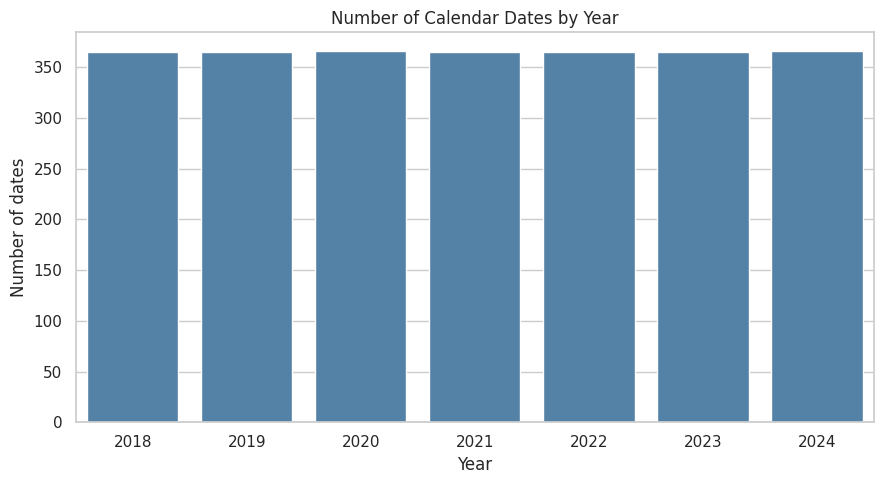

In [15]:
plt.figure(figsize=(9, 5))
sns.countplot(data=calendar, x="Year", color="steelblue")
plt.title("Number of Calendar Dates by Year")
plt.xlabel("Year")
plt.ylabel("Number of dates")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

A complete non-leap year contains 365 dates and a leap year contains 366 dates. The yearly summary helps confirm the coverage of each calendar year.

## 7. Monthly & Quarterly Distribution

,Date Count
Month Name,
January,217
February,198
March,217
April,210
May,217
June,210
July,217
August,217
September,210


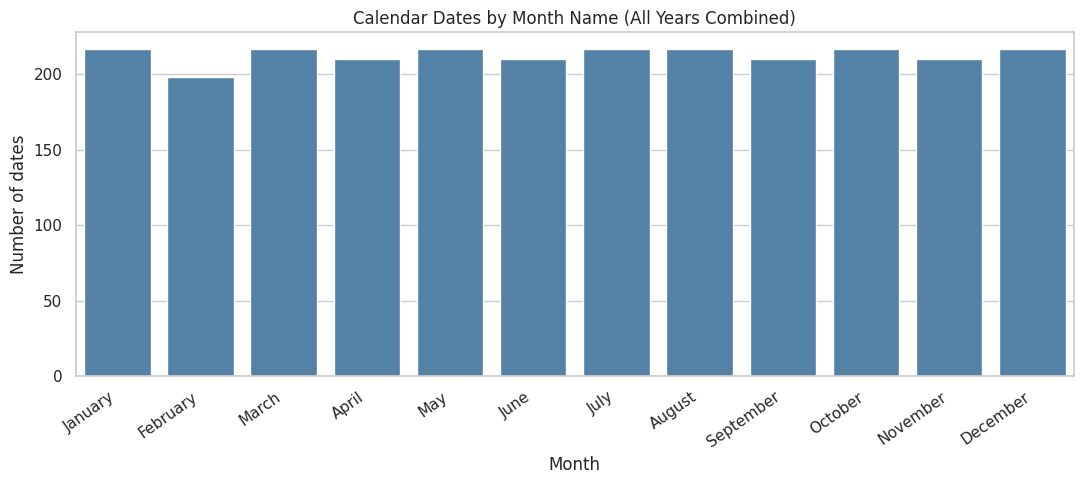

In [16]:
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
monthly_counts = calendar["Month Name"].value_counts().reindex(month_order)
display(monthly_counts.rename("Date Count").to_frame())

plt.figure(figsize=(11, 5))
sns.barplot(x=monthly_counts.index, y=monthly_counts.values, color="steelblue")
plt.title("Calendar Dates by Month Name (All Years Combined)")
plt.xlabel("Month")
plt.ylabel("Number of dates")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

,Date Count
Quarter Name,
Q1,632
Q2,637
Q3,644
Q4,644


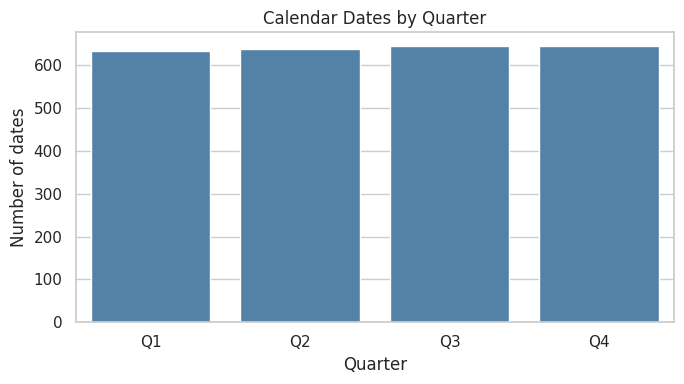

In [17]:
quarter_counts = calendar["Quarter Name"].value_counts().reindex(["Q1", "Q2", "Q3", "Q4"])
display(quarter_counts.rename("Date Count").to_frame())

plt.figure(figsize=(7, 4))
sns.barplot(x=quarter_counts.index, y=quarter_counts.values, color="steelblue")
plt.title("Calendar Dates by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Number of dates")
plt.tight_layout()
plt.show()

Month totals naturally differ because months have 28–31 days. When all years are combined, February also reflects whether leap years are included.

## 8. Weekday Analysis

,Date Count
WeekDay Name,
Monday,366
Tuesday,366
Wednesday,365
Thursday,365
Friday,365
Saturday,365
Sunday,365


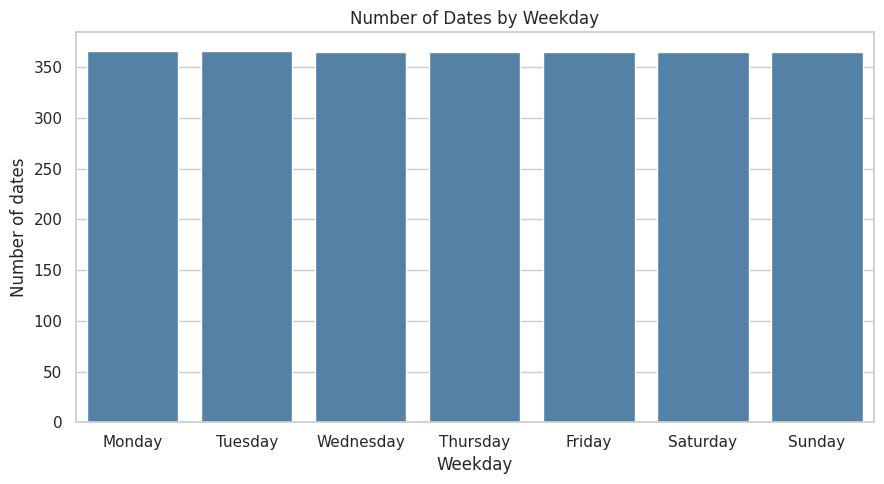

In [18]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = calendar["WeekDay Name"].value_counts().reindex(weekday_order)
display(weekday_counts.rename("Date Count").to_frame())

plt.figure(figsize=(9, 5))
sns.barplot(x=weekday_counts.index, y=weekday_counts.values, color="steelblue")
plt.title("Number of Dates by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of dates")
plt.tight_layout()
plt.show()

In [19]:
calendar["Is Weekend"].value_counts().rename(index={True: "Weekend", False: "Weekday"}).to_frame("Date Count")

,Date Count
Is Weekend,
Weekday,1827
Weekend,730


## 9. Day-of-Month & Week-Number Analysis

,Date Count
Day,
1,84
2,84
3,84
4,84
5,84
6,84
7,84
8,84
9,84


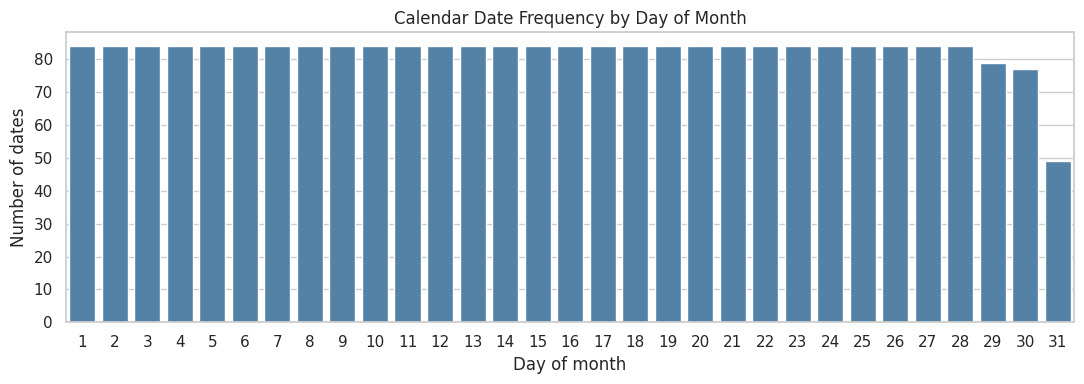

In [20]:
day_counts = calendar["Day"].value_counts().sort_index()
display(day_counts.rename("Date Count").to_frame())

plt.figure(figsize=(11, 4))
sns.barplot(x=day_counts.index, y=day_counts.values, color="steelblue")
plt.title("Calendar Date Frequency by Day of Month")
plt.xlabel("Day of month")
plt.ylabel("Number of dates")
plt.tight_layout()
plt.show()

,Date Count
Week Num,
1,31
2,49
3,49
4,49
5,49
6,49
7,49
8,49
9,49


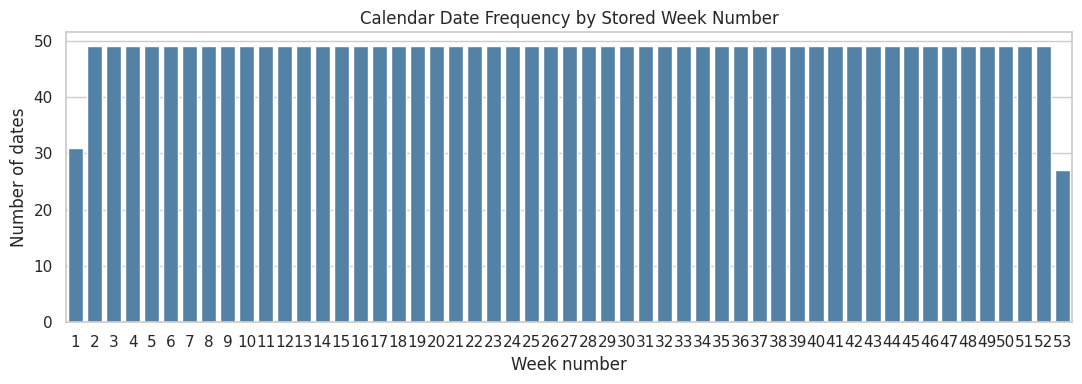

In [21]:
week_counts = calendar["Week Num"].value_counts().sort_index()
display(week_counts.rename("Date Count").to_frame())

plt.figure(figsize=(11, 4))
sns.barplot(x=week_counts.index.astype(str), y=week_counts.values, color="steelblue")
plt.title("Calendar Date Frequency by Stored Week Number")
plt.xlabel("Week number")
plt.ylabel("Number of dates")
plt.tight_layout()
plt.show()

The stored `Week Num` field is analyzed as provided. Week-number conventions can differ across systems, so it should not be assumed to follow ISO week numbering without validation.

## 10. Month-by-Year Analysis

In [22]:
month_year = calendar.pivot_table(
    index="Month",
    columns="Year",
    values="Master Date",
    aggfunc="count",
    fill_value=0
)
month_year.index = [pd.Timestamp(2000, m, 1).strftime("%B") for m in month_year.index]
month_year

Year,2018,2019,2020,2021,2022,2023,2024
January,31,31,31,31,31,31,31
February,28,28,29,28,28,28,29
March,31,31,31,31,31,31,31
April,30,30,30,30,30,30,30
May,31,31,31,31,31,31,31
June,30,30,30,30,30,30,30
July,31,31,31,31,31,31,31
August,31,31,31,31,31,31,31
September,30,30,30,30,30,30,30
October,31,31,31,31,31,31,31


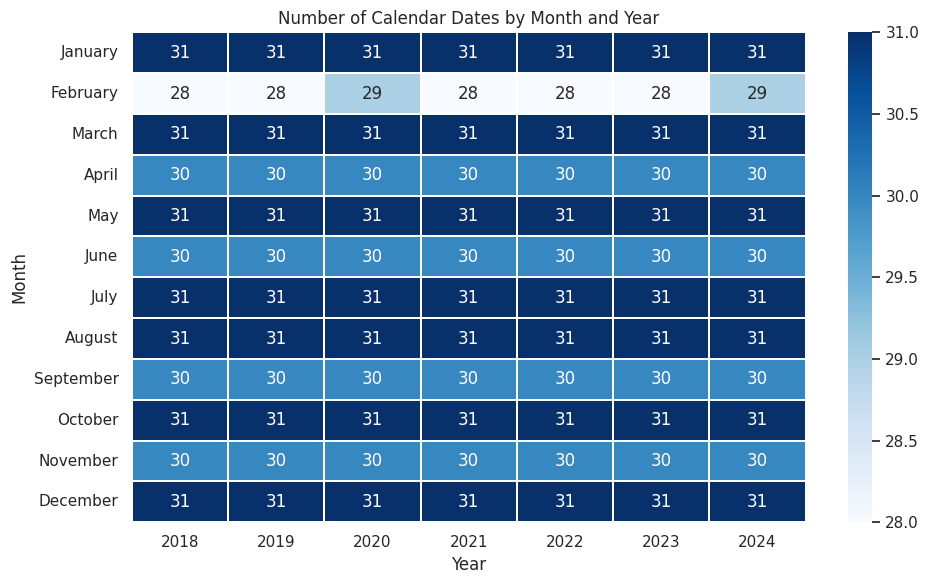

In [23]:
plt.figure(figsize=(10, 6))
sns.heatmap(month_year, annot=True, fmt="d", cmap="Blues", linewidths=0.3)
plt.title("Number of Calendar Dates by Month and Year")
plt.xlabel("Year")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

This heatmap makes it easy to compare month lengths across years and identify February differences caused by leap years.

## 11. Calendar Attribute Validation

In [24]:
# Compare the supplied date-part columns with values derived from Master Date.
validation = pd.DataFrame({
    "Check": [
        "Day matches Master Date",
        "Month matches Master Date",
        "Year matches Master Date",
        "Weekday name matches Master Date",
        "Month name matches Master Date"
    ],
    "Mismatches": [
        int((calendar["Day"] != calendar["Master Date"].dt.day).sum()),
        int((calendar["Month"] != calendar["Master Date"].dt.month).sum()),
        int((calendar["Year"] != calendar["Master Date"].dt.year).sum()),
        int((calendar["WeekDay Name"] != calendar["Master Date"].dt.day_name()).sum()),
        int((calendar["Month Name"] != calendar["Master Date"].dt.month_name()).sum())
    ]
})
validation

,Check,Mismatches
0,Day matches Master Date,0
1,Month matches Master Date,0
2,Year matches Master Date,0
3,Weekday name matches Master Date,0
4,Month name matches Master Date,0


In [25]:
# Inspect the numeric weekday convention in the supplied WeekDay column.
weekday_mapping = calendar.groupby(["WeekDay", "WeekDay Name"]).size().reset_index(name="Date Count")
weekday_mapping.sort_values(["WeekDay", "WeekDay Name"])

,WeekDay,WeekDay Name,Date Count
0,1,Sunday,365
1,2,Monday,366
2,3,Tuesday,366
3,4,Wednesday,365
4,5,Thursday,365
5,6,Friday,365
6,7,Saturday,365


The validation compares the provided day, month, year, weekday name, and month name fields with values derived from `Master Date`. The numeric `WeekDay` field is inspected separately because weekday numbering conventions vary.

## 12. Summary & Key Findings

In [26]:
summary = {
    "Total calendar dates": len(calendar),
    "Number of columns in source": dates.shape[1],
    "Start date": calendar["Master Date"].min().date(),
    "End date": calendar["Master Date"].max().date(),
    "Years covered": int(calendar["Year"].nunique()),
    "Missing values": int(calendar.isna().sum().sum()),
    "Exact duplicate rows": int(calendar.duplicated().sum()),
    "Duplicate Master Date values": int(calendar["Master Date"].duplicated().sum()),
    "Weekend dates": int(calendar["Is Weekend"].sum()),
    "Weekday dates": int((~calendar["Is Weekend"]).sum())
}
pd.Series(summary, name="Value").to_frame()

,Value
Total calendar dates,2557
Number of columns in source,8
Start date,2018-01-01
End date,2024-12-31
Years covered,7
Missing values,0
Exact duplicate rows,0
Duplicate Master Date values,0
Weekend dates,730
Weekday dates,1827


In [27]:
print("EDA SUMMARY")
print("-" * 45)
print(f"Date coverage: {calendar['Master Date'].min():%d %B %Y} to {calendar['Master Date'].max():%d %B %Y}")
print(f"Rows: {len(calendar):,} | Columns in source: {dates.shape[1]}")
print(f"Years covered: {calendar['Year'].nunique()}")
print(f"Missing values: {calendar.isna().sum().sum()}")
print(f"Duplicate rows: {calendar.duplicated().sum()}")
print(f"Duplicate dates: {calendar['Master Date'].duplicated().sum()}")
print("\nThe analysis focuses on calendar coverage, date-part frequencies, weekday/weekend patterns,")
print("and validation of the supplied calendar attributes.")

EDA SUMMARY
---------------------------------------------
Date coverage: 01 January 2018 to 31 December 2024
Rows: 2,557 | Columns in source: 8
Years covered: 7
Missing values: 0
Duplicate rows: 0
Duplicate dates: 0

The analysis focuses on calendar coverage, date-part frequencies, weekday/weekend patterns,
and validation of the supplied calendar attributes.
